# Analyse de la synthèse des dégradations (VisDrone)

Ce notebook affiche, pour chaque dégradation (**brouillard**, **pluie**, **faible lumière**) :

1. **des paires d'images** — l'image claire (GT) et sa version synthétisée ;
2. **un graphe des effectifs** — nombre d'images par dégradation pour les splits train / val / test ;
3. **des zones élargies** centrées sur les véhicules et les piétons (à partir des annotations VisDrone), pour juger de l'impact de chaque dégradation sur ces objets d'intérêt.

Les images sont appariées par nom de fichier entre `data/splits/{split}/images` (clair)
et `data/synthetic/{fog,rain,lowlight}/{split}/images` (synthétisé).
Les annotations (format VisDrone original `x1,y1,w,h,score,classe,...`) sont identiques
pour toutes les conditions car la synthèse n'applique **aucune transformation géométrique**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
from PIL import Image

%matplotlib inline

In [2]:
# ---------------------------------------------------------------- Paramètres
SPLIT = "train"   # split affiché : train, val ou test
N_PAIRS = 3       # nombre de paires clair/dégradé par dégradation
N_ZONES = 2       # nombre d'images avec zone véhicule + zone piéton
EXPAND = 2.4      # facteur d'élargissement des zones
SEED = 42

# Racines (robustes au répertoire de lancement du notebook)
REPO = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
CLEAR_ROOT = REPO / "data" / "splits"
SYNTH_ROOT = REPO / "data" / "synthetic"

DEGRADATIONS = ("fog", "rain", "lowlight")
CONDITIONS = ("clear",) + DEGRADATIONS
SPLITS = ("train", "val", "test/images")
LABELS = {
    "clear": "Ground truth (GT)",
    "fog": "Fog",
    "rain": "Rain",
    "lowlight": "Low-light",
}

# Palette catégorielle validée (mode clair) — identique à scripts/analyse_synthetisation.py
COLORS = {
    "clear": "#2a78d6", "fog": "#eb6834", "rain": "#1baf7a", "lowlight": "#eda100",
}
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
RED = "#e34948"          # contour des boîtes (rouge critique validé)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.edgecolor": BASELINE, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.sans-serif": ["DejaVu Sans"], "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110,
})

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def list_image_names(directory):
    """Noms relatifs des images d'un dossier (sans les artefacts de notebook)."""
    if not directory.is_dir():
        return set()
    return {
        str(path.relative_to(directory))
        for path in directory.rglob("*")
        if path.suffix.lower() in IMAGE_EXTENSIONS
        and ".ipynb_checkpoints" not in path.parts
    }

def matched_names(clear_root, synthetic_root, split):
    """Noms des images claires présentes pour toutes les dégradations du split."""
    sets = [list_image_names(clear_root / split / "images")]
    for degradation in DEGRADATIONS:
        folder = synthetic_root / degradation / split / "images"
        if folder.is_dir():
            sets.append(list_image_names(folder))
    return sorted(set.intersection(*sets))

def load_rgb(path):
    """Charge une image RGB en uint8."""
    return np.asarray(Image.open(path).convert("RGB"))

def parse_visdrone(path):
    """Lit une annotation VisDrone (x1, y1, w, h, score, classe, troncature, occlusion)
    et renvoie la liste [(classe, x1, y1, w, h), ...] en pixels."""
    boxes = []
    for line in Path(path).read_text().splitlines():
        parts = line.split(",")
        if len(parts) < 6:
            continue
        x1, y1, w, h = map(float, parts[:4])
        boxes.append((int(parts[5]), x1, y1, w, h))
    return boxes

def crop_zone(image, box, expand=EXPAND):
    """Recadre une zone carrée élargie autour d'une boîte (classe, x1, y1, w, h).
    Renvoie (crop, (origine_x, origine_y)) pour replacer la boîte dans le crop."""
    _, x1, y1, w, h = box
    cx, cy = x1 + w / 2, y1 + h / 2
    half = max(w, h) * expand / 2
    H, W = image.shape[:2]
    x0, x1c = max(0, int(cx - half)), min(W, int(cx + half))
    y0, y1c = max(0, int(cy - half)), min(H, int(cy + half))
    return image[y0:y1c, x0:x1c], (x0, y0)

names = matched_names(CLEAR_ROOT, SYNTH_ROOT, SPLIT)
print(f"{len(names)} images appariées clair + 3 dégradations pour le split {SPLIT}.")

5200 images appariées clair + 3 dégradations pour le split train.


## 1. Paires d'images : clair ↔ dégradé

Pour chaque dégradation, la même sélection d'images claires (colonne de gauche)
face à sa version synthétisée (colonne de droite).

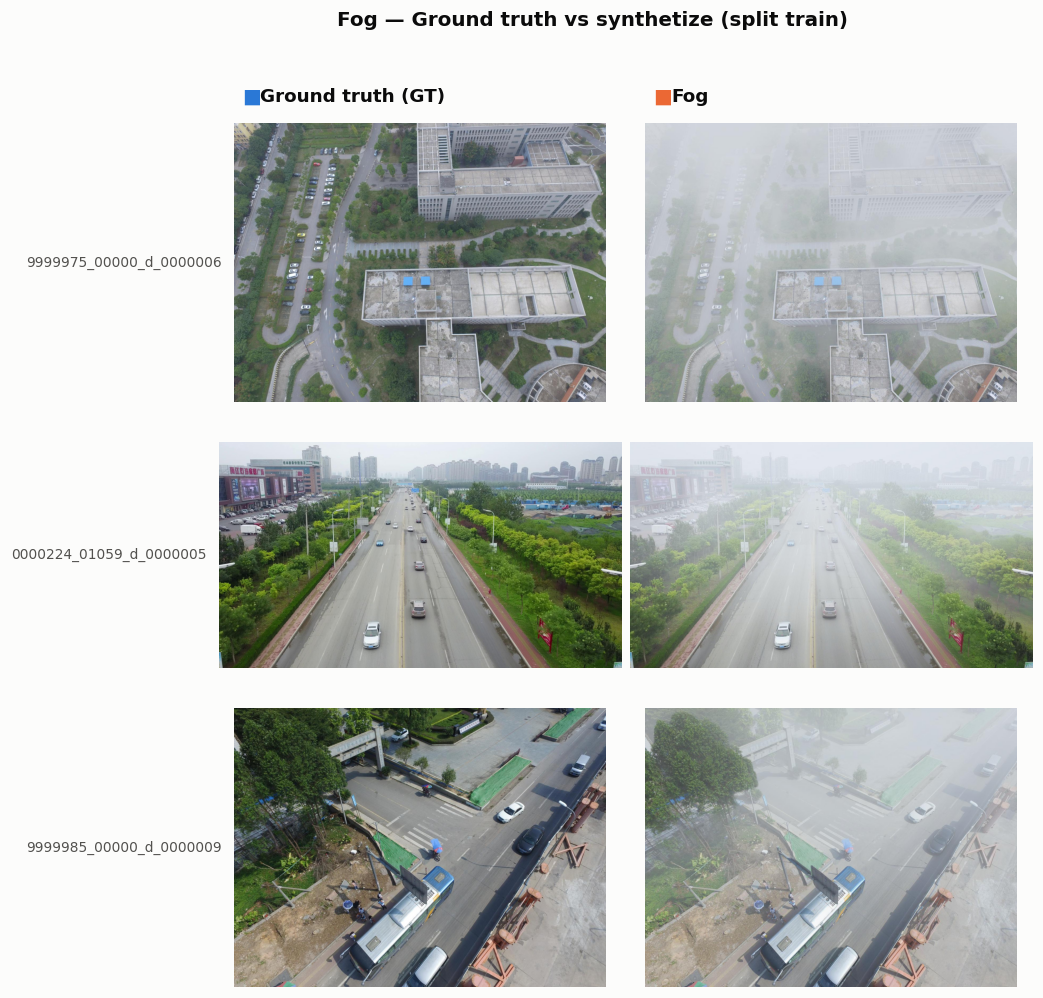

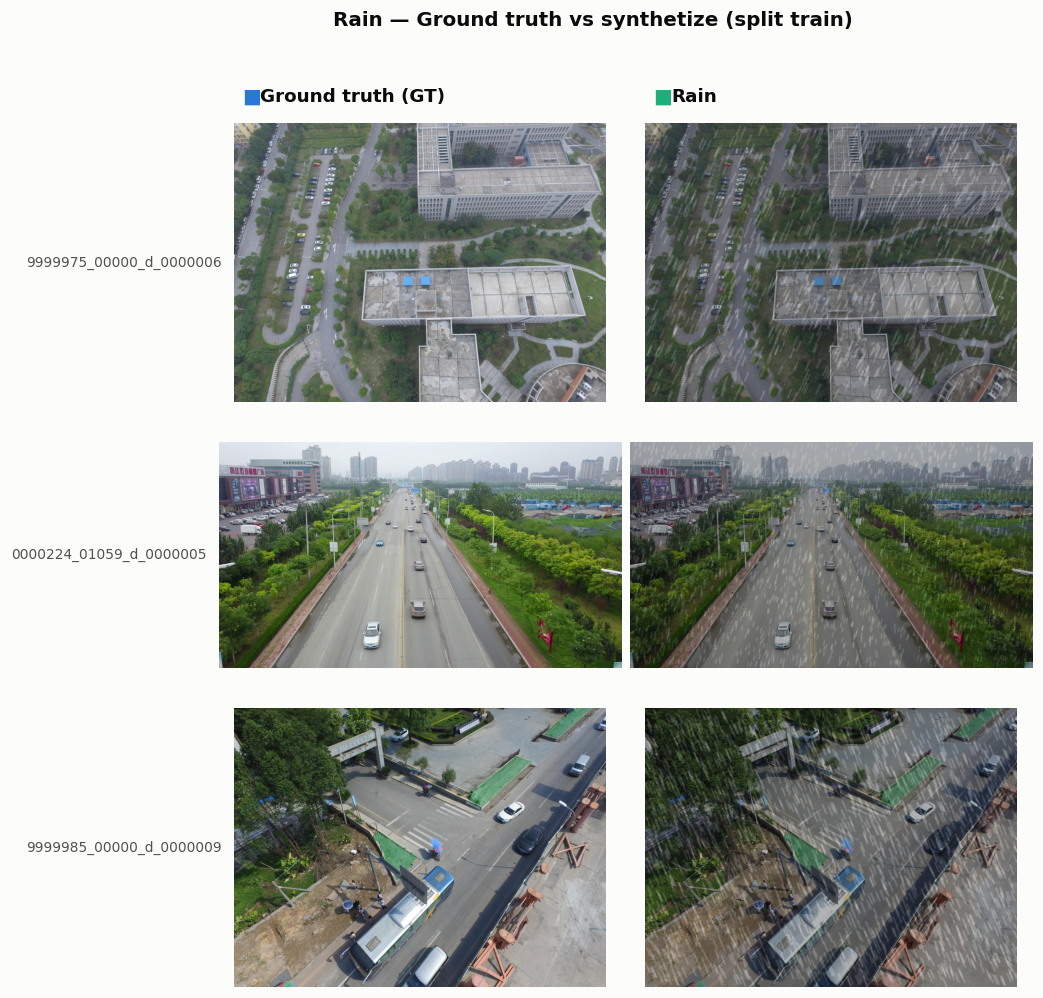

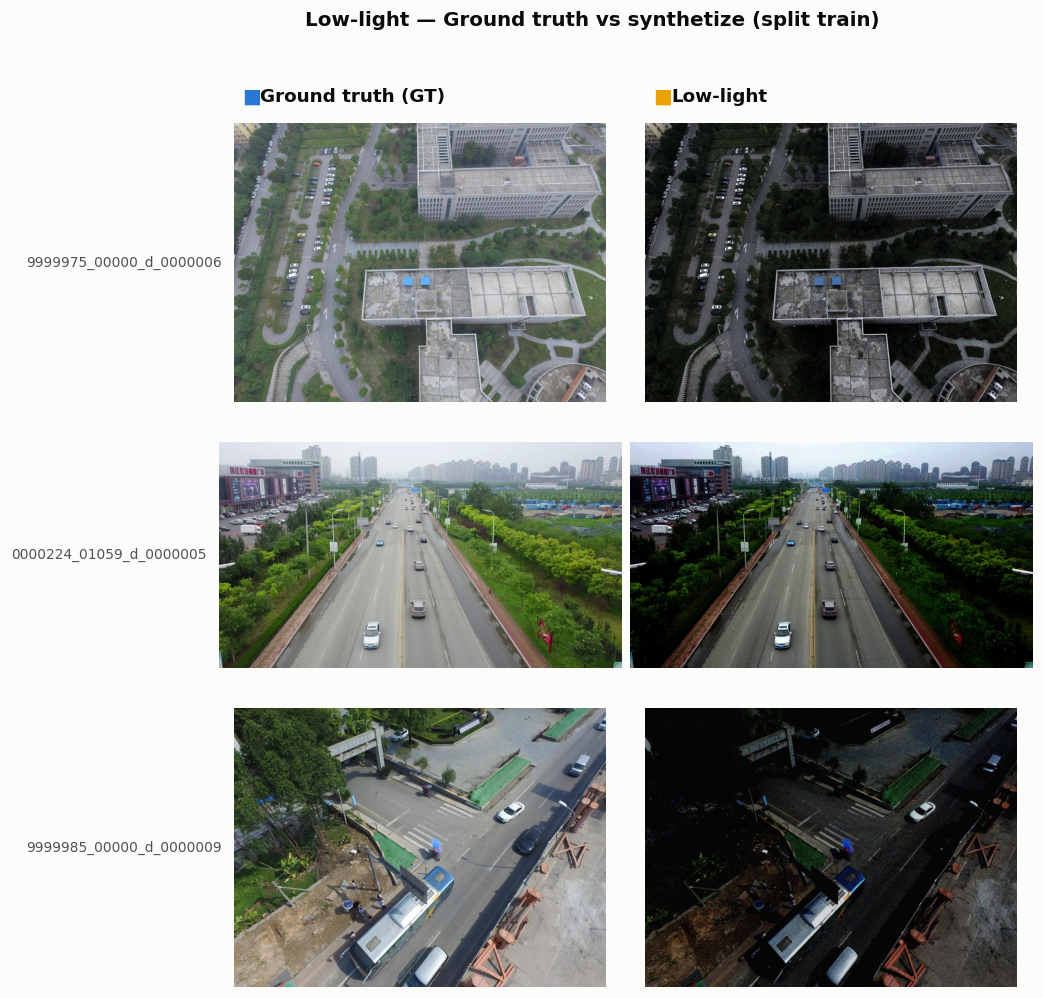

In [4]:
rng = np.random.default_rng(SEED)
pairs = list(rng.choice(names, size=min(N_PAIRS, len(names)), replace=False))

for degradation in DEGRADATIONS:
    fig, axes = plt.subplots(len(pairs), 2, figsize=(10, 3.4 * len(pairs)))
    axes = np.atleast_2d(axes)
    for row, name in enumerate(pairs):
        clear = load_rgb(CLEAR_ROOT / SPLIT / "images" / name)
        degraded = load_rgb(SYNTH_ROOT / degradation / SPLIT / "images" / name)
        axes[row, 0].imshow(clear)
        axes[row, 1].imshow(degraded)
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
        axes[row, 0].set_ylabel(Path(name).stem, rotation=0, ha="right", va="center",
                                fontsize=9, color=INK_SECONDARY, labelpad=8)
        if row == 0:
            for col, condition in enumerate(("clear", degradation)):
                axes[0, col].text(0.02, 1.06, "■", color=COLORS[condition], fontsize=13,
                                  transform=axes[0, col].transAxes, va="bottom")
                axes[0, col].text(0.07, 1.06, LABELS[condition], color=INK, fontsize=12,
                                  fontweight="bold", transform=axes[0, col].transAxes, va="bottom")
    fig.subplots_adjust(left=0.16, wspace=0.02, hspace=0.05)
    fig.suptitle(f"{LABELS[degradation]} — Ground truth vs synthetize (split {SPLIT})",
                 fontsize=13, fontweight="bold", color=INK)

    # 👇 SAVE FIRST (using fig, not plt), with a unique filename per degradation
    fig.savefig(f"degradation_{degradation}.png", dpi=300, bbox_inches="tight")

    # 👇 THEN show (optional — skip in batch scripts)
    plt.show()

    # 👇 ALWAYS close to free memory
    plt.close(fig)

## 2. Effectifs par split

Nombre d'images (paires complètes clair + 3 dégradations) pour chaque split.
Les artefacts `.ipynb_checkpoints` sont exclus ; la couverture doit être identique
pour les quatre conditions (les annotations sont copiées telles quelles).

,Ground truth (GT),Fog,Rain,Low-light
train,5200,5200,5200,5200
val,533,533,533,533
test/images,0,0,0,0


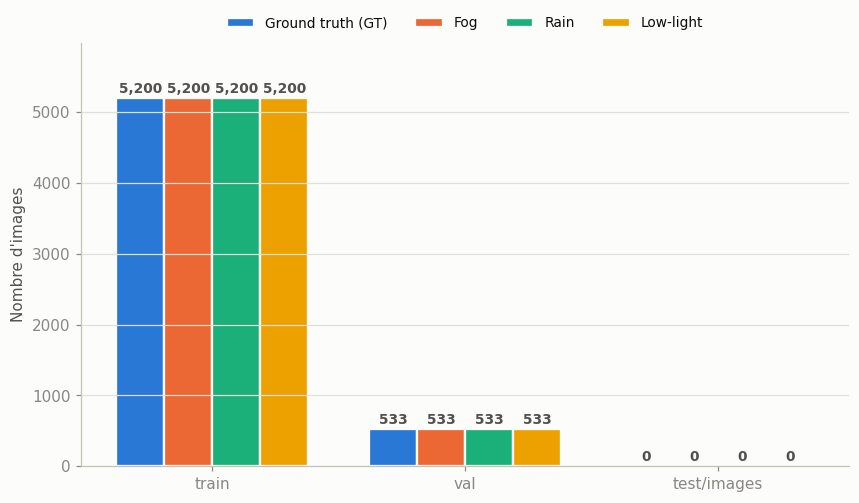

In [6]:
coverage = {}
for split in SPLITS:
    coverage[split] = {}
    for condition in CONDITIONS:
        folder = CLEAR_ROOT if condition == "clear" else SYNTH_ROOT / condition
        coverage[split][condition] = len(list_image_names(folder / split / "images"))

df = pd.DataFrame(coverage).T[list(CONDITIONS)]
df.columns = [LABELS[c] for c in CONDITIONS]
display(df)

x = np.arange(len(SPLITS))
width = 0.19
fig, ax = plt.subplots(figsize=(9, 5))
for i, condition in enumerate(CONDITIONS):
    values = [coverage[s][condition] for s in SPLITS]
    bars = ax.bar(x + (i - 1.5) * width, values, width,
                  color=COLORS[condition], label=LABELS[condition],
                  edgecolor=SURFACE, linewidth=1.5)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 30, f"{value:,}",
                ha="center", va="bottom", fontsize=9, color=INK_SECONDARY, fontweight="bold")

ax.set_xticks(x, SPLITS)
ax.set_ylabel("Nombre d'images")
ax.set_ylim(top=max(v for d in coverage.values() for v in d.values()) * 1.15)
ax.legend(fontsize=9, ncol=len(CONDITIONS), loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", visible=False)
#ax.set_title("Number of images synthesised per split and per degradation")
plt.show()

## 3. Zones élargies : véhicules et piétons

Pour quelques images contenant à la fois un piéton et un véhicule, on recadre une
**zone carrée élargie** (`EXPAND ×` la boîte) autour du plus grand objet de chaque
catégorie, pour chacune des quatre conditions. Le contour rouge reprend la boîte
d'annotation d'origine — valide dans toutes les conditions car la synthèse ne
déforme pas la géométrie.

Classes VisDrone utilisées : `0` piéton · véhicules `3` voiture, `4` van, `5` camion,
`8` bus, `9` moto.

✅ Saved: results/figures/expanded_zones/9999998_00214_d_0000170_expanded_zones.png


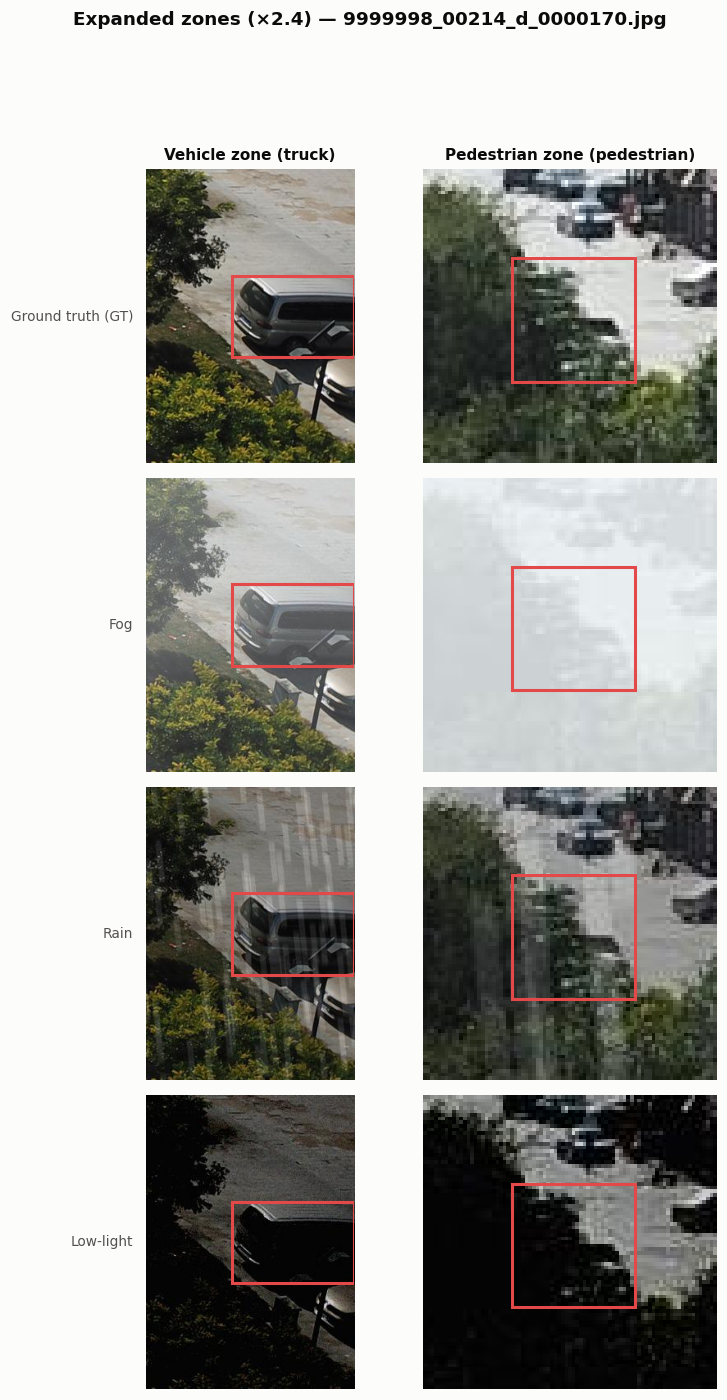

✅ Saved: results/figures/expanded_zones/9999999_00582_d_0000263_expanded_zones.png


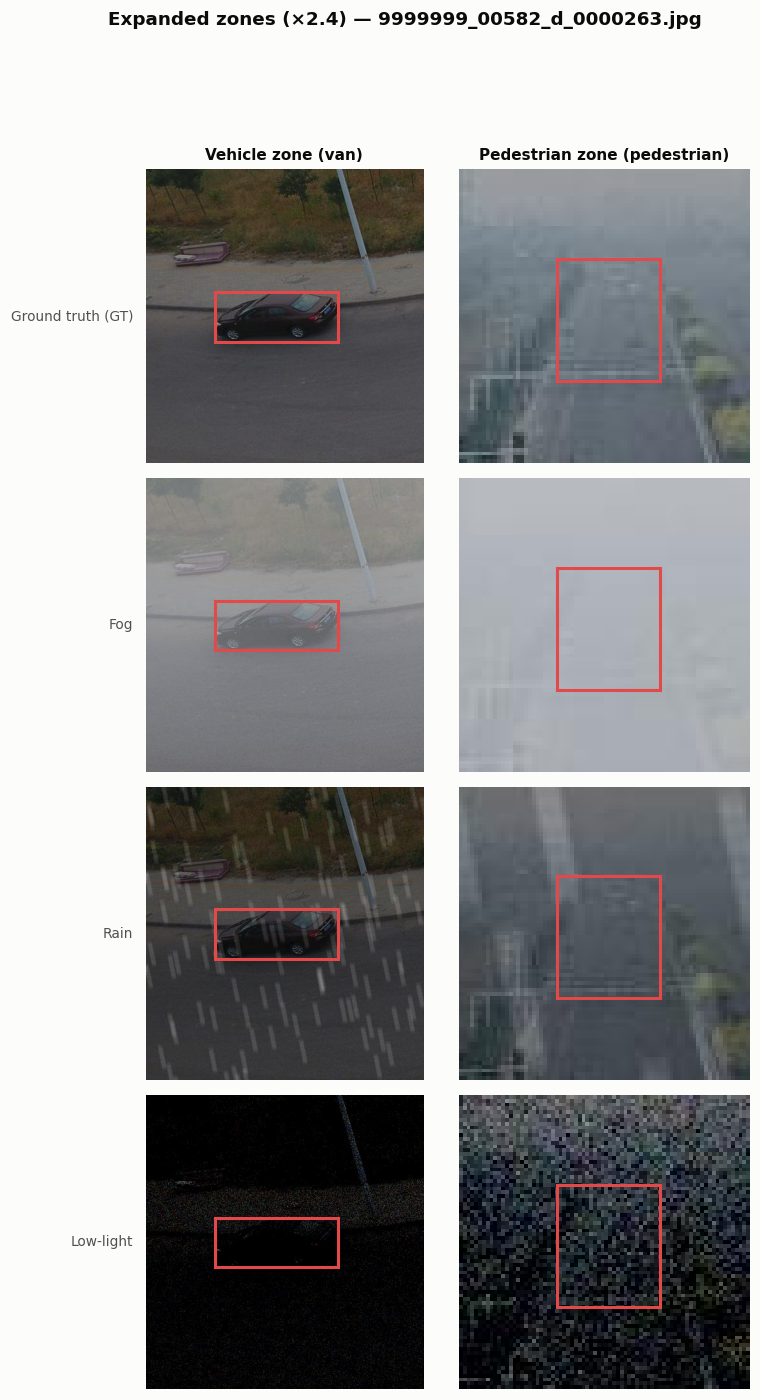

In [7]:
PEDESTRIAN_CLASSES = {0}
VEHICLE_CLASSES = {3, 4, 5, 8, 9}
CLASS_NAMES = {0: "pedestrian", 3: "car", 4: "van", 5: "truck", 8: "bus", 9: "motorcycle"}


def largest_box(boxes):
    return max(boxes, key=lambda b: b[3] * b[4])


# --- Output directory for saved figures ---
OUT_DIR = Path("results/figures/expanded_zones")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Select images containing at least one vehicle AND one pedestrian ---
rng = np.random.default_rng(SEED + 1)
selected = []

for name in rng.permutation(names):
    annotation = CLEAR_ROOT / SPLIT / "annotations" / Path(name).with_suffix(".txt")
    if not annotation.exists():
        continue

    boxes = parse_visdrone(annotation)
    pedestrians = [b for b in boxes if b[0] in PEDESTRIAN_CLASSES]
    vehicles    = [b for b in boxes if b[0] in VEHICLE_CLASSES]

    if pedestrians and vehicles:
        selected.append((name, largest_box(vehicles), largest_box(pedestrians)))

    if len(selected) >= N_ZONES:
        break


# --- Generate and save one figure per selected image ---
if not selected:
    print("⚠ No image containing both a pedestrian and a vehicle was found.")
else:
    for name, vehicle_box, pedestrian_box in selected:

        fig, axes = plt.subplots(
            len(CONDITIONS), 2,
            figsize=(8, 3.6 * len(CONDITIONS))
        )

        for row, condition in enumerate(CONDITIONS):
            folder = CLEAR_ROOT if condition == "clear" else SYNTH_ROOT / condition
            image  = load_rgb(folder / SPLIT / "images" / name)

            for col, box in enumerate((vehicle_box, pedestrian_box)):
                ax = axes[row, col]
                crop, (ox, oy) = crop_zone(image, box)
                ax.imshow(crop)

                _, x1, y1, w, h = box
                ax.add_patch(Rectangle(
                    (x1 - ox, y1 - oy), w, h,
                    fill=False, edgecolor=RED, lw=2
                ))

                ax.set_xticks([])
                ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)

                if row == 0:
                    zone = "vehicle" if col == 0 else "pedestrian"
                    ax.set_title(
                        f"{zone.capitalize()} zone ({CLASS_NAMES.get(box[0], box[0])})",
                        fontsize=10, fontweight="bold", color=INK
                    )

                if col == 0:
                    ax.set_ylabel(
                        LABELS[condition],
                        rotation=0, ha="right", va="center",
                        fontsize=9, color=INK_SECONDARY, labelpad=8
                    )

        fig.subplots_adjust(left=0.19, wspace=0.05, hspace=0.05)
        fig.suptitle(
            f"Expanded zones (×{EXPAND}) — {name}",
            fontsize=12, fontweight="bold", color=INK
        )

        # --- Save the figure (before show) ---
        out_path = OUT_DIR / f"{Path(name).stem}_expanded_zones.png"
        fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
        print(f"✅ Saved: {out_path}")

        # --- Display (optional — remove in batch mode) ---
        plt.show()

        # --- Free memory ---
        plt.close(fig)

---
**Pour aller plus loin** : le script `scripts/analyse_synthetisation.py` génère les
mêmes visuels en fichiers PNG (planche d'exemples, analyse globale : luminance,
SSIM, décalage des canaux, couverture) plus un CSV des statistiques par image.